# Step 3a — Data cleaning & local validation

This notebook explains, with plots, **how the raw BRFSS data is cleaned** and **how we estimate the test score locally** (hold-out split and stratified k-fold cross-validation).

All the logic lives in two reusable modules (so `run.py` can use exactly the same code):

| module | content |
|---|---|
| `data_cleaning.py` | `load_data`, `drop_columns`, `replace_missing_codes`, `fit_cleaner`, `transform` |
| `cross_validation.py` | metrics (`f1_score`, `accuracy`), `stratified_k_indices`, `train_val_split`, `cross_validate` |

Only NumPy + matplotlib (for plots) are used, as required by the project rules.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from data_cleaning import (load_data, drop_columns, replace_missing_codes, fit_cleaner,
                           transform, _build_features, ADMIN_COLUMNS, REDUNDANT_COLUMNS)
from cross_validation import (cross_validate, train_val_split, f1_score, accuracy,
                              best_threshold)
from implementations import ridge_regression, reg_logistic_regression

# Plot style: gray = raw / before, blue = cleaned / after, orange = positive class
RAW, CLEAN, POS = "#9a9893", "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})

## 1. Load the data

`load_data` wraps `helpers.load_csv_data` and caches the arrays in `data/dataset/cache.npz` (parsing the CSVs takes ~30 s, the cache loads in ~1 s). It also returns the column names, which the helper does not.

Labels are given in {-1, 1}; the logistic-regression methods expect {0, 1}, so we convert.

x_train: (328135, 321)  x_test: (109379, 321)
positives (MICHD): 28975 / 328135 = 8.8%


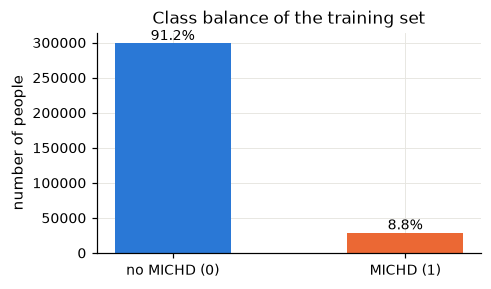

In [2]:
x_train_raw, x_test_raw, y_pm, train_ids, test_ids, columns = load_data("data/dataset")
y = (y_pm == 1).astype(float)          # {-1, 1} -> {0, 1}

print("x_train:", x_train_raw.shape, " x_test:", x_test_raw.shape)
print(f"positives (MICHD): {int(y.sum())} / {len(y)} = {y.mean():.1%}")

fig, ax = plt.subplots(figsize=(4.5, 2.6))
counts = [len(y) - y.sum(), y.sum()]
ax.bar(["no MICHD (0)", "MICHD (1)"], counts, color=[CLEAN, POS], width=0.5)
for i, c in enumerate(counts):
    ax.text(i, c, f"{c/len(y):.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("number of people"); ax.set_title("Class balance of the training set")
plt.show()

**Imbalance matters.** Only ~9% of people are positive. A model that always predicts "no" reaches ~91% accuracy but is useless, so we evaluate with the **F1 score of the positive class** (the competition metric) and keep this imbalance in mind for validation (stratified folds) and for the decision threshold.

## 2. What is wrong with the raw data?

### 2.1 Missing values

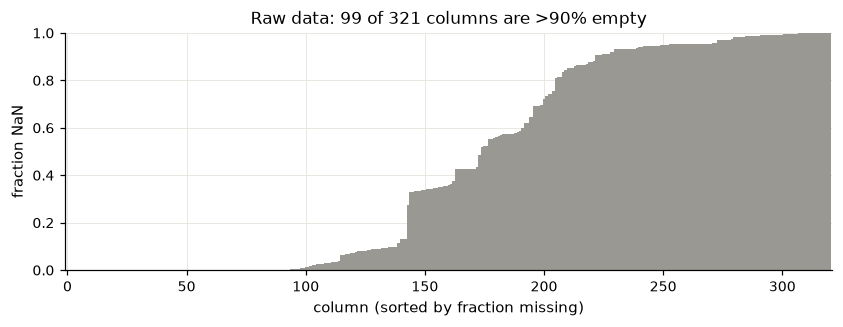

In [3]:
nan_raw = np.isnan(x_train_raw).mean(axis=0)
order = np.argsort(nan_raw)

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(np.arange(len(order)), nan_raw[order], width=1.0, color=RAW)
ax.set_xlabel("column (sorted by fraction missing)"); ax.set_ylabel("fraction NaN")
ax.set_title(f"Raw data: {np.sum(nan_raw > 0.9)} of {len(columns)} columns are >90% empty")
ax.set_xlim(-1, len(order)); ax.set_ylim(0, 1)
plt.show()

Most of the empty columns belong to **optional survey modules** asked only in some states (e.g. caregiving, vision, asthma call-back) or to **skip patterns** (e.g. "how often do you smoke?" is only asked to smokers).

### 2.2 Hidden missing values: special answer codes

The BRFSS codebook uses numbers to encode non-answers. Treating them as numbers is badly wrong — e.g. `PHYSHLTH` ("days in the last month with poor physical health", 1–30) uses **88 = none**, **77 = don't know**, **99 = refused**:

| code pattern | meaning | our treatment |
|---|---|---|
| `7`, `9` (1-digit answers) | don't know / refused | NaN (`7` kept if 1..6 are valid answers, e.g. `EMPLOY1`: 7 = retired) |
| `77`, `99` (2-digit answers) | don't know / refused | NaN |
| `777`, `999` (3-digit answers) | don't know / refused | NaN |
| `88`, `888` | "none" | 0 |
| a few exceptions (`_AGEG5YR`=14, `_DRNKWEK`=99900, ...) | missing | NaN (explicit list) |

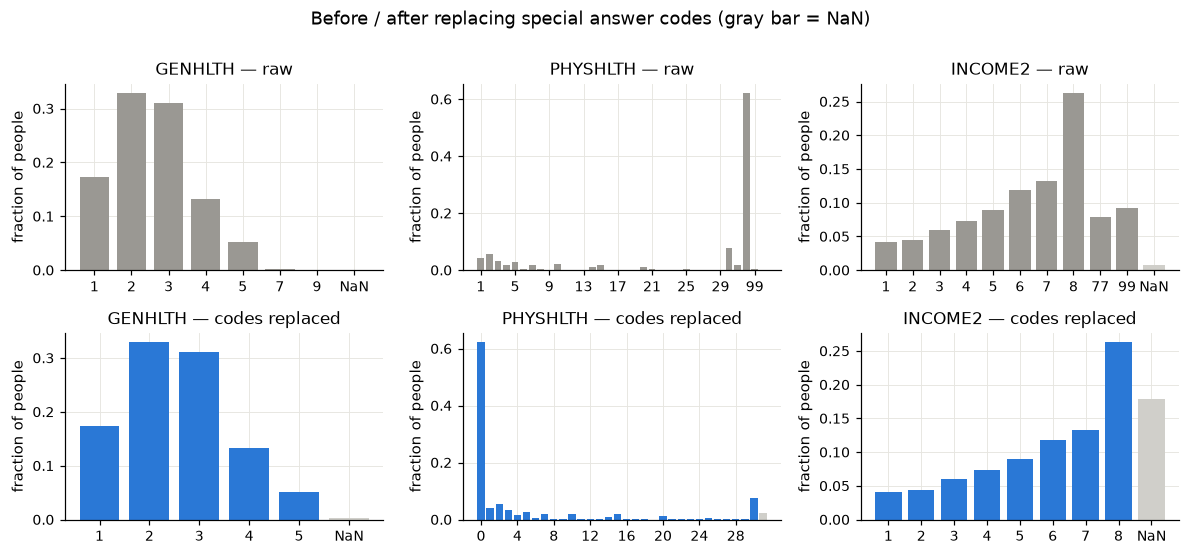

In [4]:
x_dropped, cols_dropped = drop_columns(x_train_raw, columns)
x_codes = replace_missing_codes(x_dropped, cols_dropped)

def value_bars(ax, values, color, title):
    # Bar chart of the frequency of each distinct value, plus a 'NaN' bar at the end
    v = values[~np.isnan(values)]
    u, c = np.unique(v, return_counts=True)
    labels = [str(int(a)) for a in u] + ["NaN"]
    heights = np.r_[c, np.isnan(values).sum()] / len(values)
    colors = [color] * len(u) + ["#d0cfca"]
    ax.bar(np.arange(len(labels)), heights, color=colors, width=0.8)
    step = max(1, len(labels) // 8)
    ax.set_xticks(np.arange(len(labels))[::step], labels[::step])
    ax.set_title(title); ax.set_ylabel("fraction of people")

examples = ["GENHLTH", "PHYSHLTH", "INCOME2"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for k, name in enumerate(examples):
    j_raw = np.where(columns == name)[0][0]
    j_new = np.where(cols_dropped == name)[0][0]
    value_bars(axes[0, k], x_train_raw[:, j_raw], RAW, f"{name} — raw")
    value_bars(axes[1, k], x_codes[:, j_new], CLEAN, f"{name} — codes replaced")
fig.suptitle("Before / after replacing special answer codes (gray bar = NaN)", y=1.0)
fig.tight_layout(); plt.show()

- `GENHLTH` (1 = excellent … 5 = poor): the `7` and `9` bars become NaN.
- `PHYSHLTH`: the huge `88` bar ("no bad day") **moves to 0**, which is its real meaning, and `77`/`99` become NaN. Without this, the healthiest people would look like the sickest (88 > 30)!
- `INCOME2`: income brackets 1–8, codes `77`/`99` become NaN (≈18% of people did not answer).

## 3. The cleaning pipeline

### Step 1 — drop columns that carry no health information (stateless)
- **Administrative / survey design**: interview date, sequence number, phone-line questions, sampling weights (`_LLCPWT`...), state.
- **Redundant raw answers** with a weird encoding (e.g. `FRUIT1`: 1xx = per day, 2xx = per week…) for which the survey already provides a clean calculated version (`FRUTDA1_` = fruit per day), plus `WEIGHT2`/`HEIGHT3` (mixed units, replaced by `WTKG3`, `HTM4`, `_BMI5`).

In [5]:
print(f"{len(ADMIN_COLUMNS)} admin columns + {len(REDUNDANT_COLUMNS)} redundant columns dropped")
print(f"{len(columns)} -> {len(cols_dropped)} columns")

33 admin columns + 19 redundant columns dropped
321 -> 269 columns


### Step 2 — replace special codes by NaN (stateless)
Done above with `replace_missing_codes`. The rules are applied per column and only to integer-valued columns (continuous calculated variables are left untouched). These two steps do not learn anything from the data, so they can safely be applied to the whole train and test sets once.

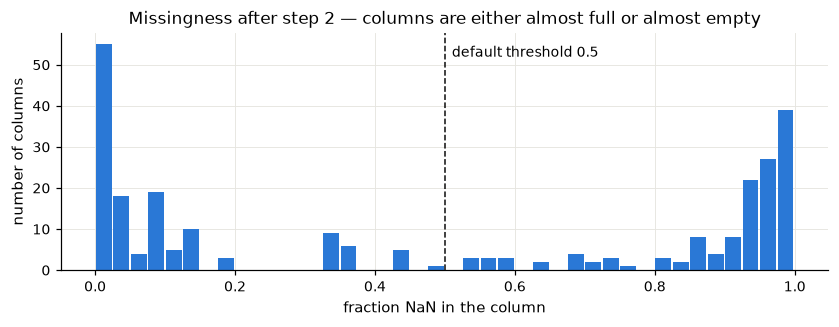

max_nan_frac = 0.3: keep 114 / 269 columns
max_nan_frac = 0.5: keep 135 / 269 columns
max_nan_frac = 0.7: keep 150 / 269 columns
max_nan_frac = 0.9: keep 173 / 269 columns
max_nan_frac = 1.0: keep 269 / 269 columns


In [6]:
nan_codes = np.isnan(x_codes).mean(axis=0)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.hist(nan_codes, bins=40, color=CLEAN, rwidth=0.9)
ax.axvline(0.5, color="#0b0b0b", lw=1, ls="--")
ax.text(0.51, ax.get_ylim()[1] * 0.9, "default threshold 0.5", fontsize=9)
ax.set_xlabel("fraction NaN in the column"); ax.set_ylabel("number of columns")
ax.set_title("Missingness after step 2 — columns are either almost full or almost empty")
plt.show()
for t in [0.3, 0.5, 0.7, 0.9, 1.0]:
    print(f"max_nan_frac = {t:.1f}: keep {np.sum(nan_codes <= t):3d} / {len(nan_codes)} columns")

### Steps 3–6 — `fit_cleaner` / `transform` (learned on the training data only)

| step | what | parameter learned on train |
|---|---|---|
| 3 | drop columns with more than `max_nan_frac` NaN | which columns |
| 4 | one-hot encode nominal columns (`MARITAL`, `EMPLOY1`, `_RACE`, `RENTHOM1`) — their codes have no order | list of categories |
| 5 | clip continuous columns (> 20 distinct values) to the [0.5%, 99.5%] quantiles | quantiles |
| 6 | impute NaN with the median (optionally add a 0/1 "was missing" column) | medians |
| 7 | drop constant columns, standardize to mean 0 / std 1, add a bias column | means, stds |

**Why fit/transform?** Every statistic (median, quantile, mean, std) must be computed on the training data only and then *re-used* on validation/test data. Computing them on all data would leak information from the validation set into training and make the validation score optimistic.

**Why standardize?** Features live on very different scales (BMI ≈ 28, minutes of activity ≈ thousands, yes/no = 1/2). Gradient descent with one step size `gamma` converges badly when scales differ, and the ridge penalty λ‖w‖² would penalize features unequally.

In [7]:
params = fit_cleaner(x_codes, cols_dropped)
tx = transform(x_codes, params)
print("cleaned matrix:", tx.shape, "(including bias column)")
print("any NaN left?", np.isnan(tx).any())

cleaned matrix: (328135, 157) (including bias column)
any NaN left? False


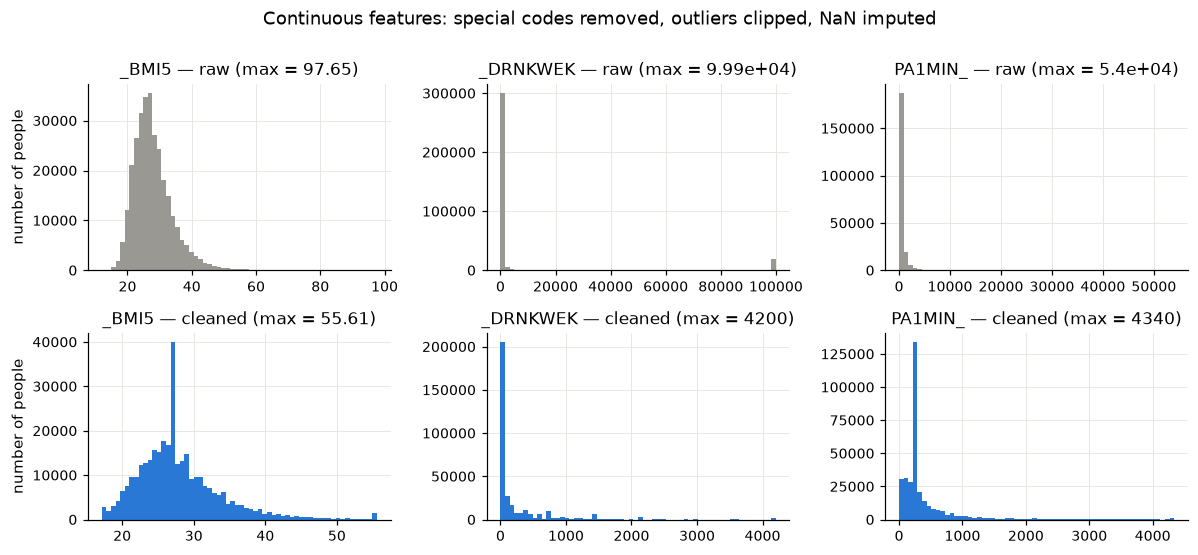

In [8]:
# Continuous features: raw -> after codes/clipping/imputation (before scaling)
z_unscaled = _build_features(x_codes, params)
unscaled_names = list(cols_dropped[params["numeric_idx"]])

examples = ["_BMI5", "_DRNKWEK", "PA1MIN_"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for k, name in enumerate(examples):
    raw = x_train_raw[:, np.where(columns == name)[0][0]]
    raw = raw[~np.isnan(raw)]
    axes[0, k].hist(raw, bins=60, color=RAW)
    axes[0, k].set_title(f"{name} — raw (max = {raw.max():.4g})")
    after = z_unscaled[:, unscaled_names.index(name)]
    axes[1, k].hist(after, bins=60, color=CLEAN)
    axes[1, k].set_title(f"{name} — cleaned (max = {after.max():.4g})")
for ax in axes[:, 0]:
    ax.set_ylabel("number of people")
fig.suptitle("Continuous features: special codes removed, outliers clipped, NaN imputed", y=1.0)
fig.tight_layout(); plt.show()

- `_BMI5`: long right tail (BMI up to 97) clipped at the 99.5% quantile.
- `_DRNKWEK` (drinks per week): the raw histogram is dominated by the code **99900 = missing**; after cleaning we see the real distribution.
- `PA1MIN_` (minutes of activity per week): extreme values (54 000 min/week ≈ 128 h/day!) are clearly data errors and get clipped.

The median-imputation spike (a tall bar at the median) is visible — it is the price of simple imputation; the "was missing" indicators (`add_nan_indicators=True`) let the model know that the value was imputed.

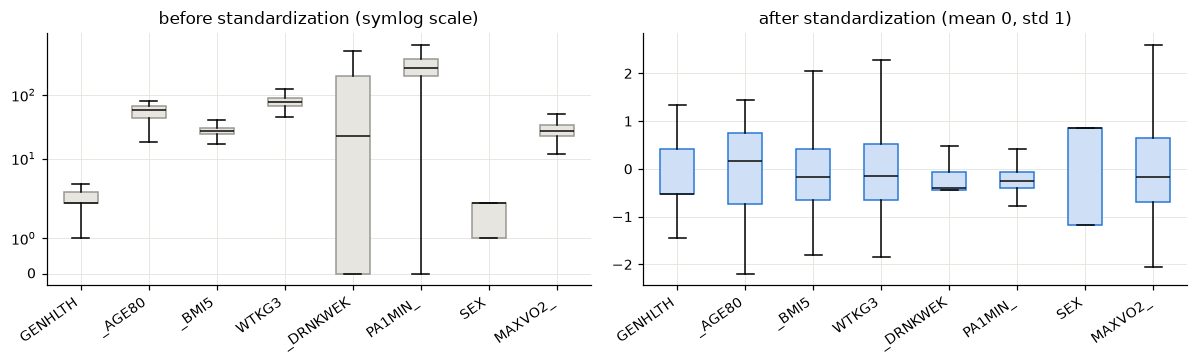

In [9]:
# Scales before vs after standardization
names = list(params["feature_names"])
show = ["GENHLTH", "_AGE80", "_BMI5", "WTKG3", "_DRNKWEK", "PA1MIN_", "SEX", "MAXVO2_"]
idx = [names.index(n) for n in show]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].boxplot([z_unscaled[::20, params["keep_features"]][:, i] for i in idx],
                showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#e6e5e0", color=RAW), medianprops=dict(color="#0b0b0b"))
axes[0].set_yscale("symlog"); axes[0].set_title("before standardization (symlog scale)")
axes[1].boxplot([tx[::20, 1 + i] for i in idx], showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="#cfe0f6", color=CLEAN), medianprops=dict(color="#0b0b0b"))
axes[1].set_title("after standardization (mean 0, std 1)")
for ax in axes:
    ax.set_xticks(range(1, len(show) + 1), show, rotation=35, ha="right")
fig.tight_layout(); plt.show()

### Sanity check: which cleaned features are most related to heart disease?

A quick look at the correlation between each cleaned feature and the label. If the cleaning is right, the top features should make medical sense.

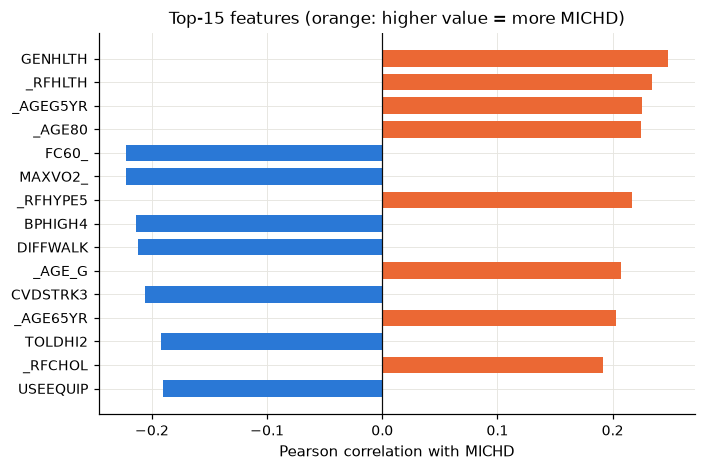

In [10]:
feat = tx[:, 1:]
corr = ((feat - feat.mean(0)) * (y - y.mean())[:, None]).mean(0) / (feat.std(0) * y.std())
top = np.argsort(-np.abs(corr))[:15][::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(np.array(names)[top], corr[top], color=[POS if c > 0 else CLEAN for c in corr[top]], height=0.7)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Pearson correlation with MICHD")
ax.set_title("Top-15 features (orange: higher value = more MICHD)")
plt.show()

The top features are general health, age, high blood pressure, high cholesterol, stroke, difficulty walking, use of special equipment… — exactly the known cardiovascular risk factors. (`MAXVO2_`/`FC60_` are fitness estimates the survey computes *from age and sex*, hence their strong correlation.) Note that for yes/no questions, **1 = yes, 2 = no**, so a negative correlation for e.g. `_RFHYPE5`/`CVDSTRK3` means "yes → more MICHD" — the model does not care about the sign, but keep it in mind when interpreting weights.

## 4. Local validation

We must never tune anything on the AIcrowd leaderboard (5 submissions/day, and it overfits the public test set). Instead we estimate the test score locally.

**Rules we follow**
1. **Stratified splits** — each fold keeps the ~9% positive rate, so fold scores are comparable.
2. **The cleaner is re-fitted inside each fold** (on the training part only) → no leakage.
3. **The decision threshold is chosen on the training part**, then applied to the validation part. The threshold matters a lot for F1 with imbalanced classes (see below).

### 4.1 Hold-out validation set (fast, for quick experiments)

In [11]:
def sigmoid(t):
    return 1 / (1 + np.exp(-t))

def train_logreg(y, tx, lambda_=1e-4, iters=300, gamma=0.5):
    w, _ = reg_logistic_regression(y, tx, lambda_, np.zeros(tx.shape[1]), iters, gamma)
    return w

x_tr, x_val, y_tr, y_val = train_val_split(y, x_codes, val_ratio=0.2, seed=1)
print(f"train {len(y_tr)} ({y_tr.mean():.2%} pos) | val {len(y_val)} ({y_val.mean():.2%} pos)")

p = fit_cleaner(x_tr, cols_dropped)            # fitted on the training part only
tx_tr, tx_val = transform(x_tr, p), transform(x_val, p)
w = train_logreg(y_tr, tx_tr)

thr, f1_tr = best_threshold(y_tr, sigmoid(tx_tr @ w))
pred_val = (sigmoid(tx_val @ w) >= thr).astype(int)
print(f"threshold chosen on train: {thr:.3f} (train F1 {f1_tr:.4f})")
print(f"validation F1 = {f1_score(y_val, pred_val):.4f}, accuracy = {accuracy(y_val, pred_val):.4f}")
print(f"validation F1 with threshold 0.5 = {f1_score(y_val, (sigmoid(tx_val @ w) >= 0.5).astype(int)):.4f}")

train 262508 (8.83% pos) | val 65627 (8.83% pos)


threshold chosen on train: 0.194 (train F1 0.4264)
validation F1 = 0.4275, accuracy = 0.8687
validation F1 with threshold 0.5 = 0.2194


### 4.2 Stratified 5-fold cross-validation (more reliable, gives a standard deviation)

Each sample is used for validation exactly once. The spread across folds tells us whether a difference between two configurations is real or just noise.

In [12]:
models = {
    "ridge regression (λ=1e-4)": (lambda y, tx: ridge_regression(y, tx, 1e-4)[0],
                                  lambda tx, w: tx @ w),
    "logistic regression (λ=1e-4)": (train_logreg, lambda tx, w: sigmoid(tx @ w)),
}
results = {}
for name, (train_fn, predict_fn) in models.items():
    r = cross_validate(y, x_codes, cols_dropped, train_fn, predict_fn, k_fold=5, seed=1)
    results[name] = r
    print(f"{name:30s} F1 = {r['f1'].mean():.4f} ± {r['f1'].std():.4f} | "
          f"acc = {r['accuracy'].mean():.4f} | F1 folds = {np.round(r['f1'], 4)}")

ridge regression (λ=1e-4)      F1 = 0.4155 ± 0.0068 | acc = 0.8620 | F1 folds = [0.4223 0.4064 0.4225 0.4178 0.4086]


logistic regression (λ=1e-4)   F1 = 0.4241 ± 0.0051 | acc = 0.8698 | F1 folds = [0.4275 0.4163 0.4314 0.4231 0.4223]


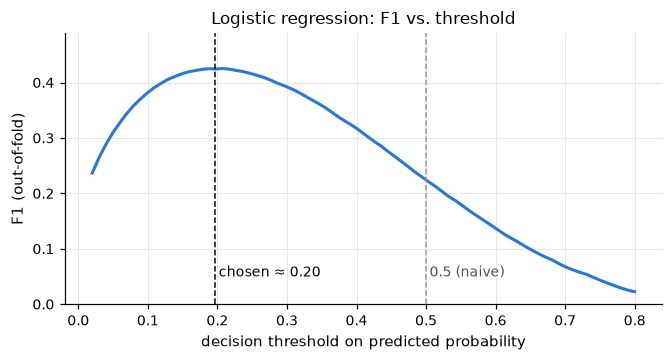

In [13]:
# Why the threshold matters: F1 as a function of the threshold (out-of-fold scores)
oof = results["logistic regression (λ=1e-4)"]["oof_scores"]
ts = np.linspace(0.02, 0.8, 80)
f1s = [f1_score(y, (oof >= t).astype(int)) for t in ts]
chosen = results["logistic regression (λ=1e-4)"]["threshold"].mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ts, f1s, color=CLEAN, lw=2)
ax.axvline(0.5, color=RAW, ls="--", lw=1); ax.text(0.505, 0.05, "0.5 (naive)", fontsize=9, color="#52514e")
ax.axvline(chosen, color="#0b0b0b", ls="--", lw=1); ax.text(chosen + 0.005, 0.05, f"chosen ≈ {chosen:.2f}", fontsize=9)
ax.set_xlabel("decision threshold on predicted probability"); ax.set_ylabel("F1 (out-of-fold)")
ax.set_title("Logistic regression: F1 vs. threshold"); ax.set_ylim(0, max(f1s) * 1.15)
plt.show()

With 9% positives, predicted probabilities are rarely above 0.5, so the naive threshold misses most sick people. Lowering the threshold to ≈0.2 roughly **doubles** the F1 score.

### 4.3 Using CV to compare cleaning choices (mini ablation)

This is how cross-validation will be used in the rest of step 3: change one thing at a time, and keep it only if the CV score improves by more than the fold-to-fold noise.

default (NaN≤0.5, clip)            F1 = 0.4241 ± 0.0051


no outlier clipping                F1 = 0.4244 ± 0.0047


NaN≤0.9 + missing indicators       F1 = 0.4264 ± 0.0044


keep all + missing indicators      F1 = 0.4378 ± 0.0045


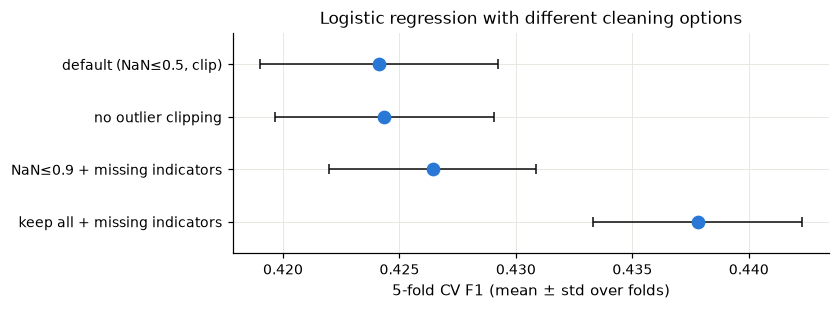

In [14]:
variants = {
    "default (NaN≤0.5, clip)":            dict(max_nan_frac=0.5),
    "no outlier clipping":                dict(max_nan_frac=0.5, clip_quantiles=None),
    "NaN≤0.9 + missing indicators":       dict(max_nan_frac=0.9, add_nan_indicators=True),
    "keep all + missing indicators":      dict(max_nan_frac=1.0, add_nan_indicators=True),
}
abl = {}
for name, kw in variants.items():
    r = cross_validate(y, x_codes, cols_dropped, train_logreg, lambda tx, w: sigmoid(tx @ w),
                       k_fold=5, seed=1, cleaner_kwargs=kw)
    abl[name] = r["f1"]
    print(f"{name:34s} F1 = {r['f1'].mean():.4f} ± {r['f1'].std():.4f}")

fig, ax = plt.subplots(figsize=(7, 2.6))
labels = list(abl)[::-1]
means = [abl[k].mean() for k in labels]
ax.errorbar(means, np.arange(len(labels)), xerr=[abl[k].std() for k in labels], fmt="o",
            color=CLEAN, ms=8, ecolor="#0b0b0b", elinewidth=1, capsize=3)
ax.set_yticks(np.arange(len(labels)), labels); ax.set_ylim(-0.6, len(labels) - 0.4)
ax.set_xlabel("5-fold CV F1 (mean ± std over folds)")
ax.set_title("Logistic regression with different cleaning options")
plt.show()

**Reading the result.** Clipping makes no difference (within noise). Keeping the sparse columns *with missing indicators* helps clearly (+0.014, ≈3 std): in this survey, **whether a question was asked is itself informative** (skip patterns, e.g. "how often do you smoke" is only asked to smokers).

⚠️ One extreme case: `HAREHAB1` ("did you go to cardiac rehab after your heart attack?") is only answered by people who had a heart attack → 100% of them are positive. It is present in `x_test` as well (0.22% of rows), so using it is allowed, but it is a form of label leakage from the questionnaire design and deserves a sentence in the report.

## 5. Summary

**Cleaning pipeline** (in `data_cleaning.py`):
1. drop admin / redundant columns → 2. special codes → NaN (88 → 0) → 3. drop mostly-empty columns → 4. one-hot nominal columns → 5. clip outliers → 6. median imputation (+ optional missing indicators) → 7. standardize + bias.

**Validation** (in `cross_validation.py`): stratified hold-out split for quick checks, stratified 5-fold CV for decisions; the cleaner and the threshold are always fitted on the training part only. F1 is the metric; tuning the threshold is essential with 9% positives.

**Next steps** (rest of step 3): tune λ / γ / iterations with CV, feature engineering (polynomial features, interactions, log transforms of skewed features), handling class imbalance (class weights, resampling), and the final `run.py`.